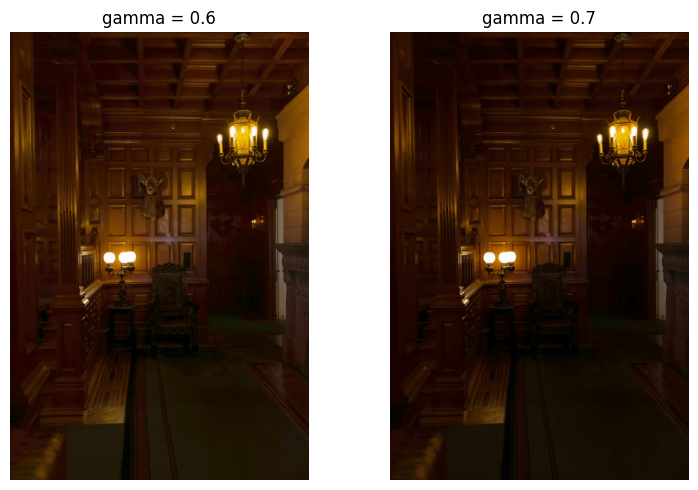

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def adjust_gamma(image: np.ndarray, gamma: float, c=1) -> np.ndarray:
  if gamma <= 0:
    raise ValueError("Gamma must be non-negative.")

  normalized = image.astype(np.float32) / 255.0
  corrected = np.power(normalized, gamma)
  corrected = c*corrected
  return np.clip(corrected * 255.0, 0, 255).astype(np.uint8)


img_bgr = cv2.imread("./files/darkly_lit_room.jpg", cv2.IMREAD_COLOR)
if img_bgr is None:
  raise FileNotFoundError("Image not found!")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gammas = [0.6, 0.7]

fig, axes = plt.subplots(1, len(gammas), figsize=(8, 5))

# axes[0].imshow(img_rgb)
# axes[0].set_title("Original image")
# axes[0].axis("off")

for idx, g in enumerate(gammas, start=0):
  gamma_bgr = adjust_gamma(img_bgr, gamma=g)
  gamma_rgb = cv2.cvtColor(gamma_bgr, cv2.COLOR_BGR2RGB)
  axes[idx].imshow(gamma_rgb)
  axes[idx].set_title(f"gamma = {g}")
  axes[idx].axis("off")

plt.tight_layout()
plt.show()

Level 0 pyramid -> dimensions: (256, 256)
Level 1 pyramid -> dimensions: (128, 128)
Level 2 pyramid -> dimensions: (64, 64)
Reconstruction MSE: 0.0000


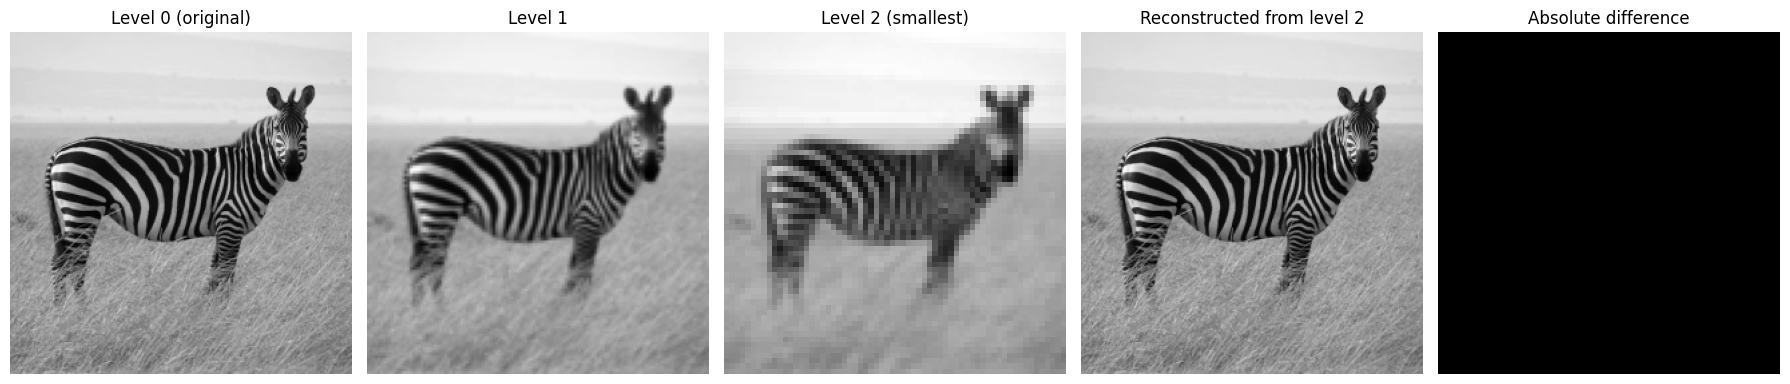

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def gaussian_kernel_2d(size: int = 5, sigma: float = 1.0) -> np.ndarray:
  ax = np.arange(-(size // 2), size // 2 + 1, dtype=np.float64)
  kernel_1d = np.exp(-(ax**2) / (2.0 * sigma**2))
  kernel_1d /= np.sum(kernel_1d)
  kernel_2d = np.outer(kernel_1d, kernel_1d)
  return kernel_2d / np.sum(kernel_2d)

def convolution(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
  k_h, k_w = kernel.shape
  pad_h, pad_w = k_h // 2, k_w // 2
  kernel_flipped = np.flipud(np.fliplr(kernel)) # flip from left to right and then from up to down

  if image.ndim == 2:
    h, w = image.shape
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    output = np.zeros((h, w), dtype=np.float64)
    for i in range(h):
      for j in range(w):
        patch = padded[i : i + k_h, j : j + k_w]
        output[i, j] = np.sum(patch * kernel_flipped)
    return output

  elif image.ndim == 3:
    h, w, c = image.shape
    output = np.zeros((h, w, c), dtype=np.float64)
    for ch in range(c):
      output[:, :, ch] = convolution(image[:, :, ch], kernel)
    return output

  else:
    raise ValueError("Array must be 2D or 3D.")


def downsample_2x(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
  smoothed = convolution(image, kernel)
  return smoothed[::2, ::2]


def upsample_to_shape(
    image: np.ndarray, target_shape: tuple[int, ...], kernel: np.ndarray
) -> np.ndarray:
  up = np.zeros(target_shape, dtype=np.float64)
  up[::2, ::2] = image[: up[::2, ::2].shape[0], : up[::2, ::2].shape[1]]
  return convolution(up * 4.0, kernel)


def build_three_level_pyramid(image: np.ndarray, kernel: np.ndarray):
  level_0 = image.astype(np.float64)
  level_1 = downsample_2x(level_0, kernel)
  level_2 = downsample_2x(level_1, kernel)

  up_1_to_0 = upsample_to_shape(level_1, level_0.shape, kernel)
  detail_0 = level_0 - up_1_to_0

  up_2_to_1 = upsample_to_shape(level_2, level_1.shape, kernel)
  detail_1 = level_1 - up_2_to_1

  gaussian_pyramid = [level_0, level_1, level_2]
  details = [detail_0, detail_1]
  return gaussian_pyramid, details


def reconstruct_from_smallest_level(
    smallest_level: np.ndarray, details: list[np.ndarray], kernel: np.ndarray
) -> np.ndarray:

  detail_0, detail_1 = details

  reconstructed_1 = (
      upsample_to_shape(smallest_level, detail_1.shape, kernel) + detail_1
  )

  reconstructed_0 = (
      upsample_to_shape(reconstructed_1, detail_0.shape, kernel) + detail_0
  )

  return np.clip(reconstructed_0, 0, 255).astype(np.float64)


img = cv2.imread("./files/zebra.png", cv2.IMREAD_GRAYSCALE)
if img is None:
  raise FileNotFoundError("Couldn't find image.")

kernel = gaussian_kernel_2d(size=5, sigma=1.0)

pyr, details = build_three_level_pyramid(img, kernel)
for idx, lvl in enumerate(pyr):
  print(f"Level {idx} pyramid -> dimensions: {lvl.shape}")

reconstructed = reconstruct_from_smallest_level(pyr[2], details, kernel)

cv2.imwrite("reconstructed.jpg", reconstructed)

mse = np.mean(
    (img.astype(np.float64) - reconstructed.astype(np.float64)) ** 2
)
print(f"Reconstruction MSE: {mse:.4f}")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
titles = [
    "Level 0 (original)",
    "Level 1",
    "Level 2 (smallest)",
    "Reconstructed from level 2",
    "Absolute difference",
]
# imgs = [
#     cv2.cvtColor(np.clip(pyr[0], 0, 255).astype(np.uint8), cv2.COLOR_BGR2RGB),
#     cv2.cvtColor(np.clip(pyr[1], 0, 255).astype(np.uint8), cv2.COLOR_BGR2RGB),
#     cv2.cvtColor(np.clip(pyr[2], 0, 255).astype(np.uint8), cv2.COLOR_BGR2RGB),
#     cv2.cvtColor(reconstructed, cv2.COLOR_BGR2RGB),
#     cv2.cvtColor(
#         np.abs(img.astype(np.float64) - reconstructed.astype(np.float64))
#         .clip(0, 255)
#         .astype(np.uint8),
#         cv2.COLOR_BGR2RGB,
#     ),
# ]

imgs = [
    np.clip(pyr[0], 0, 255).astype(np.uint8),
    np.clip(pyr[1], 0, 255).astype(np.uint8),
    np.clip(pyr[2], 0, 255).astype(np.uint8),
    np.clip(reconstructed, 0, 255).astype(np.uint8),
    np.abs(
        img.astype(np.float64) - reconstructed.astype(np.float64)
    ).clip(0, 255).astype(np.uint8),
]

for ax, im, title in zip(axes, imgs, titles):
  ax.imshow(im, cmap="gray")
  ax.set_title(title)
  ax.axis("off")

plt.tight_layout()
plt.show()

level 0 pyramid -> dimensions: (256, 256)
level 1 pyramid -> dimensions: (128, 128)
level 2 pyramid -> dimensions: (64, 64)
MSE of reconstruction: 73.7740


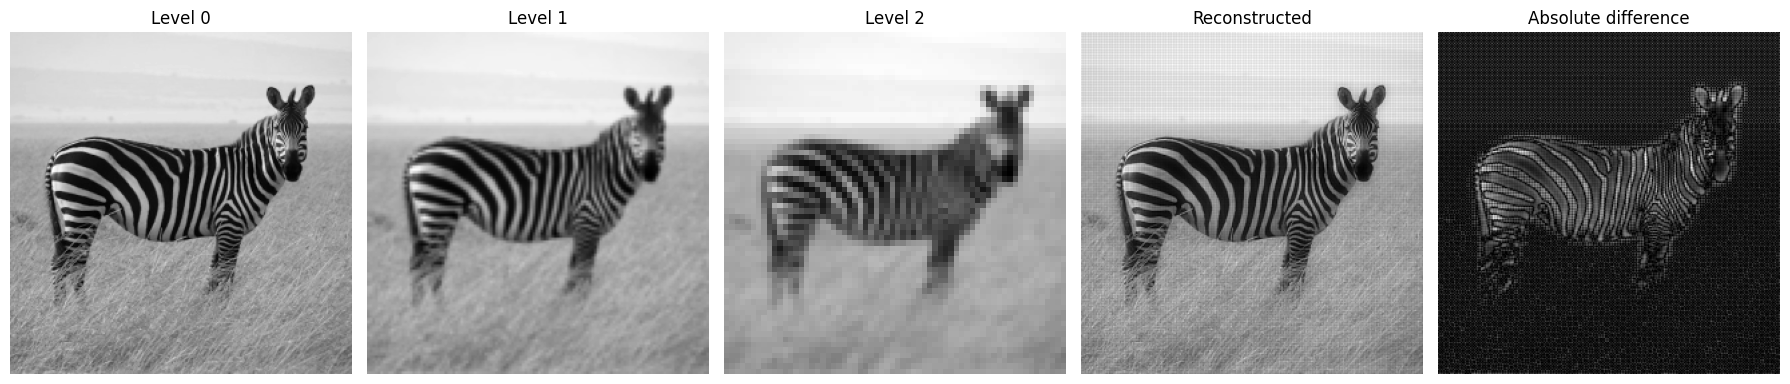

In [4]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def gaussian_kernel_2d(size: int = 5, sigma: float = 1.0) -> np.ndarray:
  ax = np.arange(-(size // 2), size // 2 + 1, dtype=np.float64)
  kernel_1d = np.exp(-(ax**2) / (2.0 * sigma**2))
  kernel_1d /= np.sum(kernel_1d)
  kernel_2d = np.outer(kernel_1d, kernel_1d)
  return kernel_2d / np.sum(kernel_2d)


def convolution(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
  k_h, k_w = kernel.shape
  pad_h, pad_w = k_h // 2, k_w // 2
  kernel_flipped = np.flipud(np.fliplr(kernel))

  if image.ndim == 2:
    h, w = image.shape
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    output = np.zeros((h, w), dtype=np.float64)
    for i in range(h):
      for j in range(w):
        patch = padded[i : i + k_h, j : j + k_w]
        output[i, j] = np.sum(patch * kernel_flipped)
    return output

  elif image.ndim == 3:
    h, w, c = image.shape
    output = np.zeros((h, w, c), dtype=np.float64)
    for ch in range(c):
      output[:, :, ch] = convolution(image[:, :, ch], kernel)
    return output

  else:
    raise ValueError("Array must be 2D or 3D.")


def downsample_2x(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
  smoothed = convolution(image, kernel)
  return smoothed[::2, ::2]


def upsample_to_shape(
    image: np.ndarray, target_shape: tuple[int, ...], kernel: np.ndarray
) -> np.ndarray:
  up = np.zeros(target_shape, dtype=np.float64)
  up[::2, ::2] = image[: up[::2, ::2].shape[0], : up[::2, ::2].shape[1]]
  return convolution(up * 4.0, kernel)


# [CHANGED] Build a 3-level pyramid following the slide algorithm:
# repeat: filter (blur) -> compute residual (current - blurred) -> subsample
def build_three_level_pyramid(image: np.ndarray, kernel: np.ndarray):
  current = image.astype(np.float64)
  levels = [current]
  details = []  # Stores residual of each level

  for _ in range(2):
    blurred = convolution(current, kernel)  # Filter (Blur)
    residual = current - blurred  # Compute residual
    next_level = blurred[::2, ::2]  # Subsample blurred image

    details.append(residual)
    levels.append(next_level)
    current = next_level

  return levels, details


# [CHANGED] Reconstruct from smallest level (levels[2]) back to level 0
def reconstruct_from_smallest_level(
    smallest_level: np.ndarray, details: list[np.ndarray], kernel: np.ndarray
) -> np.ndarray:
  detail_0, detail_1 = details  # [CHANGED] Two residuals correspond to 2 upsample steps

  # [CHANGED] Step 1: Upsample smallest level (level 2) to level 1 shape and add residual 1
  reconstructed_1 = (
      upsample_to_shape(smallest_level, detail_1.shape, kernel) + detail_1
  )

  # [CHANGED] Step 2: Upsample reconstructed level 1 to level 0 shape and add residual 0
  reconstructed_0 = (
      upsample_to_shape(reconstructed_1, detail_0.shape, kernel) + detail_0
  )

  return np.clip(reconstructed_0, 0, 255).astype(np.float64)


img = cv2.imread("./files/zebra.png", cv2.IMREAD_GRAYSCALE)
if img is None:
  raise FileNotFoundError("Image not found")

kernel = gaussian_kernel_2d(size=5, sigma=1.0)

pyr, details = build_three_level_pyramid(img, kernel)
for idx, lvl in enumerate(pyr):
  print(f"level {idx} pyramid -> dimensions: {lvl.shape}")

reconstructed = reconstruct_from_smallest_level(pyr[2], details, kernel)

cv2.imwrite("reconstructed.jpg", reconstructed)

mse = np.mean(
    (img.astype(np.float64) - reconstructed.astype(np.float64)) ** 2
)
print(f"MSE of reconstruction: {mse:.4f}")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
titles = [
    "Level 0",
    "Level 1",
    "Level 2",
    "Reconstructed",
    "Absolute difference",
]
# imgs_rgb = [
#     cv2.cvtColor(np.clip(pyr[0], 0, 255).astype(np.uint8), cv2.COLOR_BGR2RGB),
#     cv2.cvtColor(np.clip(pyr[1], 0, 255).astype(np.uint8), cv2.COLOR_BGR2RGB),
#     cv2.cvtColor(np.clip(pyr[2], 0, 255).astype(np.uint8), cv2.COLOR_BGR2RGB),
#     cv2.cvtColor(reconstructed, cv2.COLOR_BGR2RGB),
#     cv2.cvtColor(
#         np.abs(img.astype(np.float64) - reconstructed.astype(np.float64))
#         .clip(0, 255)
#         .astype(np.uint8),
#         cv2.COLOR_BGR2RGB,
#     ),
# ]

imgs = [
    np.clip(pyr[0], 0, 255).astype(np.uint8),
    np.clip(pyr[1], 0, 255).astype(np.uint8),
    np.clip(pyr[2], 0, 255).astype(np.uint8),
    np.clip(reconstructed, 0, 255).astype(np.uint8),
    np.abs(
        img.astype(np.float64) - reconstructed.astype(np.float64)
    ).clip(0, 255).astype(np.uint8),
]

for ax, im, title in zip(axes, imgs, titles):
  ax.imshow(im, cmap="gray")
  ax.set_title(title)
  ax.axis("off")

plt.tight_layout()
plt.show()

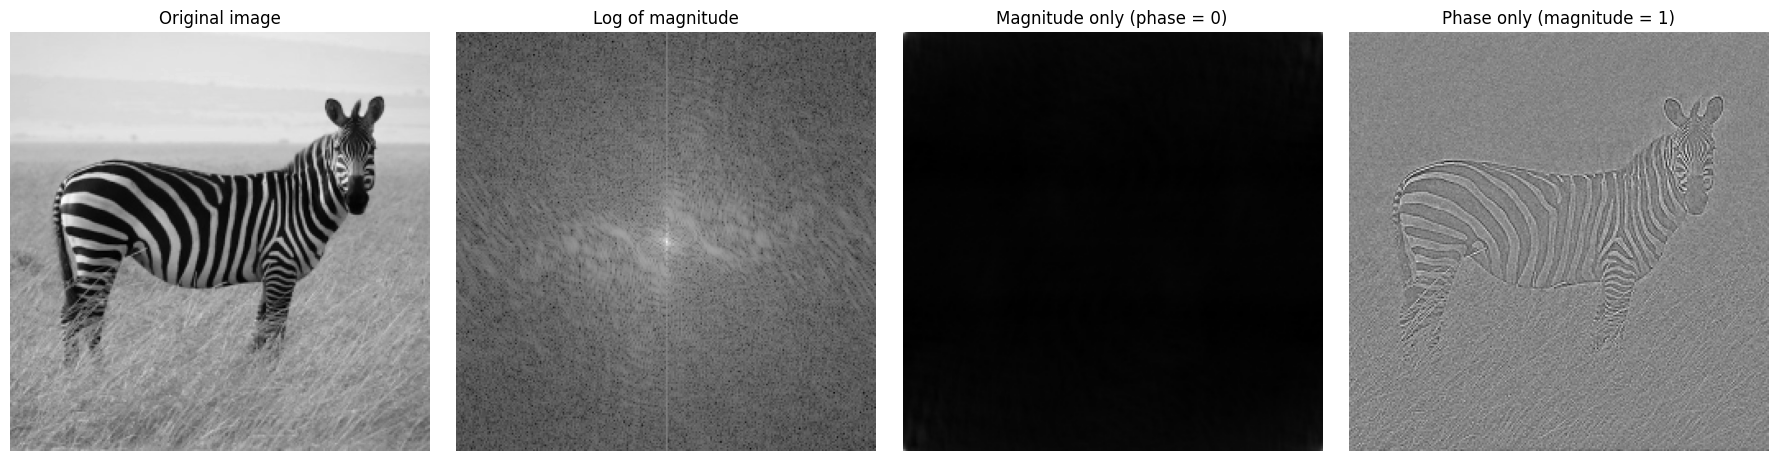

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def normalize_for_display(arr: np.ndarray) -> np.ndarray:
  arr_float = arr.astype(np.float64)
  min_val = np.min(arr_float)
  max_val = np.max(arr_float)
  if max_val - min_val == 0:
    return np.zeros_like(arr_float, dtype=np.uint8)
  norm = (arr_float - min_val) / (max_val - min_val) * 255.0
  return np.clip(norm, 0, 255).astype(np.uint8)


def reconstruct_magnitude_only_zero_phase(channel: np.ndarray) -> np.ndarray:
  dft = np.fft.fft2(channel.astype(np.float64))
  magnitude = np.abs(dft)
  spec_zero_phase = magnitude * np.exp(1j * 0.0)
  spatial_rec = np.real(np.fft.ifft2(spec_zero_phase))
  return normalize_for_display(spatial_rec)


def reconstruct_phase_only_unit_magnitude(channel: np.ndarray) -> np.ndarray:
  dft = np.fft.fft2(channel.astype(np.float64))
  phase = np.angle(dft)
  spec_unit_mag = 1.0 * np.exp(1j * phase)
  spatial_rec = np.real(np.fft.ifft2(spec_unit_mag))
  return normalize_for_display(spatial_rec)


# خواندن تصویر با OpenCV (به صورت سطح خاکستری برای تحلیل کلاسیک DFT)
img_gray = cv2.imread("./files/zebra.png", cv2.IMREAD_GRAYSCALE)
if img_gray is None:
  raise FileNotFoundError("Image not found.")

dft_shift = np.fft.fftshift(np.fft.fft2(img_gray.astype(np.float64)))
magnitude_spectrum = np.log1p(np.abs(dft_shift))
magnitude_vis = normalize_for_display(magnitude_spectrum)

# بخش الف: حفظ اندازه، فاز صفر
img_mag_only = reconstruct_magnitude_only_zero_phase(img_gray)

# بخش ب: حفظ فاز، اندازه برابر یک
img_phase_only = reconstruct_phase_only_unit_magnitude(img_gray)

# ذخیره خروجی‌ها با OpenCV
cv2.imwrite("dft_magnitude_spectrum.png", magnitude_vis)
cv2.imwrite("reconstructed_mag_only_zero_phase.png", img_mag_only)
cv2.imwrite("reconstructed_phase_only_unit_mag.png", img_phase_only)

# نمایش تصاویر با matplotlib
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].imshow(img_gray, cmap="gray")
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(magnitude_vis, cmap="gray")
axes[1].set_title("Log of magnitude")
axes[1].axis("off")

axes[2].imshow(img_mag_only, cmap="gray")
axes[2].set_title("Magnitude only (phase = 0)")
axes[2].axis("off")

axes[3].imshow(img_phase_only, cmap="gray")
axes[3].set_title("Phase only (magnitude = 1)")
axes[3].axis("off")

plt.tight_layout()
plt.show()

Frobenius norm of the difference of the two methods: 0.000000000000
2D method multiplications: 2,359,296 | Additions: 2,097,152 | Overall Operations: 4,456,448
1D method multiplications: 1,572,864 | Additions: 1,048,576 | overall operations: 2,621,440


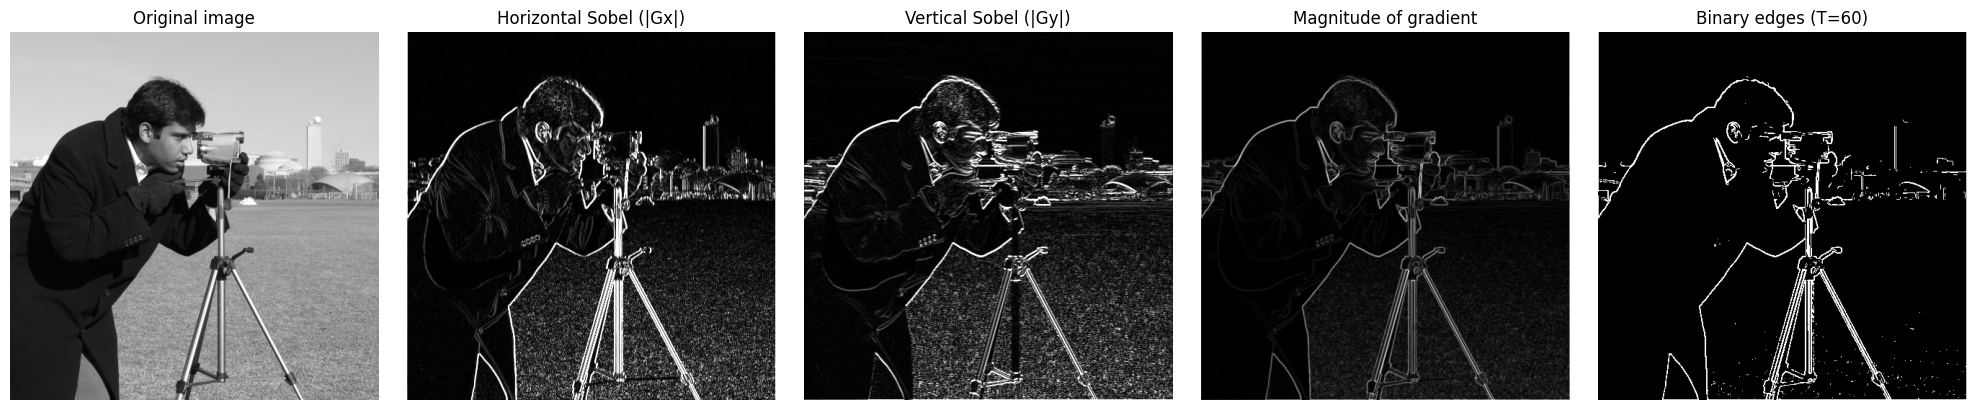

In [7]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def convolve_same_zero_pad(
    image: np.ndarray, kernel: np.ndarray
) -> np.ndarray:

  kernel_flipped = np.flipud(np.fliplr(kernel)).astype(np.float64)
  return cv2.filter2D(
      image.astype(np.float64),
      ddepth=cv2.CV_64F,
      kernel=kernel_flipped,
      borderType=cv2.BORDER_CONSTANT,
  )


img = cv2.imread("./files/cameraman.png", cv2.IMREAD_GRAYSCALE)
if img is None:
  raise FileNotFoundError("Image not found.")

H, W = img.shape

# ==============================================================================
# Sobel, both vertical and horizontal
# ==============================================================================
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)

sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64)

grad_x = convolve_same_zero_pad(img, sobel_x)
grad_y_2d = convolve_same_zero_pad(img, sobel_y)

grad_x_vis = np.clip(np.abs(grad_x), 0, 255).astype(np.uint8)
grad_y_vis = np.clip(np.abs(grad_y_2d), 0, 255).astype(np.uint8)
cv2.imwrite("sobel_gx.png", grad_x_vis)
cv2.imwrite("sobel_gy.png", grad_y_vis)

# ==============================================================================
# Vertical Sobel as two 1D filters
# ==============================================================================
# [-1, 0, 1]^T * [1, 2, 1] = sobel_y
k_vertical = np.array([[-1], [0], [1]], dtype=np.float64)
k_horizontal = np.array([[1, 2, 1]], dtype=np.float64)

temp = convolve_same_zero_pad(img, k_vertical)
grad_y_1d = convolve_same_zero_pad(temp, k_horizontal)

grad_y_vis_1d = np.clip(np.abs(grad_y_1d), 0, 255).astype(np.uint8)
cv2.imwrite("sobel_gy_1d.png", grad_y_vis_1d)

diff = grad_y_2d - grad_y_1d
frobenius_norm = np.linalg.norm(diff, ord="fro")
print(
    "Frobenius norm of the difference of the two methods:"
    f" {frobenius_norm:.12f}"
)

# محاسبه و مقایسه تعداد عملیات ضرب و جمع (برای تصویر با ابعاد H x W و کرنل 3x3)
num_pixels = H * W

# روش 2D (کرنل 3x3 = 9 درایه برای هر پیکسل)
mults_2d = num_pixels * 9
adds_2d = num_pixels * 8

# روش 1D متوالی (دو مرحله، هر مرحله کرنل 3 تایی برای هر پیکسل)
mults_1d = num_pixels * (3 + 3)
adds_1d = num_pixels * (2 + 2)

print(
    f"2D method multiplications: {mults_2d:,} | Additions: {adds_2d:,} | Overall"
    f" Operations: {mults_2d + adds_2d:,}"
)
print(
    f"1D method multiplications: {mults_1d:,} | Additions: {adds_1d:,} | overall"
    f" operations: {mults_1d + adds_1d:,}"
)

# ==============================================================================
# بخش ج: تصویر اندازه گرادیان و آستانه‌گذاری باینری
# ==============================================================================
gradient_magnitude = np.sqrt(grad_x**2 + grad_y_2d**2)
grad_mag_vis = np.clip(
    (gradient_magnitude / np.max(gradient_magnitude)) * 255.0, 0, 255
).astype(np.uint8)

threshold = 60
binary_edges = np.where(grad_mag_vis >= threshold, 255, 0).astype(np.uint8)

cv2.imwrite("gradient_magnitude.png", grad_mag_vis)
cv2.imwrite(f"binary_edges_{threshold}.png", binary_edges)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
titles = [
    "Original image",
    "Horizontal Sobel (|Gx|)",
    "Vertical Sobel (|Gy|)",
    "Magnitude of gradient",
    f"Binary edges (T={threshold})",
]
images = [img, grad_x_vis, grad_y_vis, grad_mag_vis, binary_edges]

for ax, im, title in zip(axes, images, titles):
  ax.imshow(im, cmap="gray")
  ax.set_title(title)
  ax.axis("off")

plt.tight_layout()
plt.show()

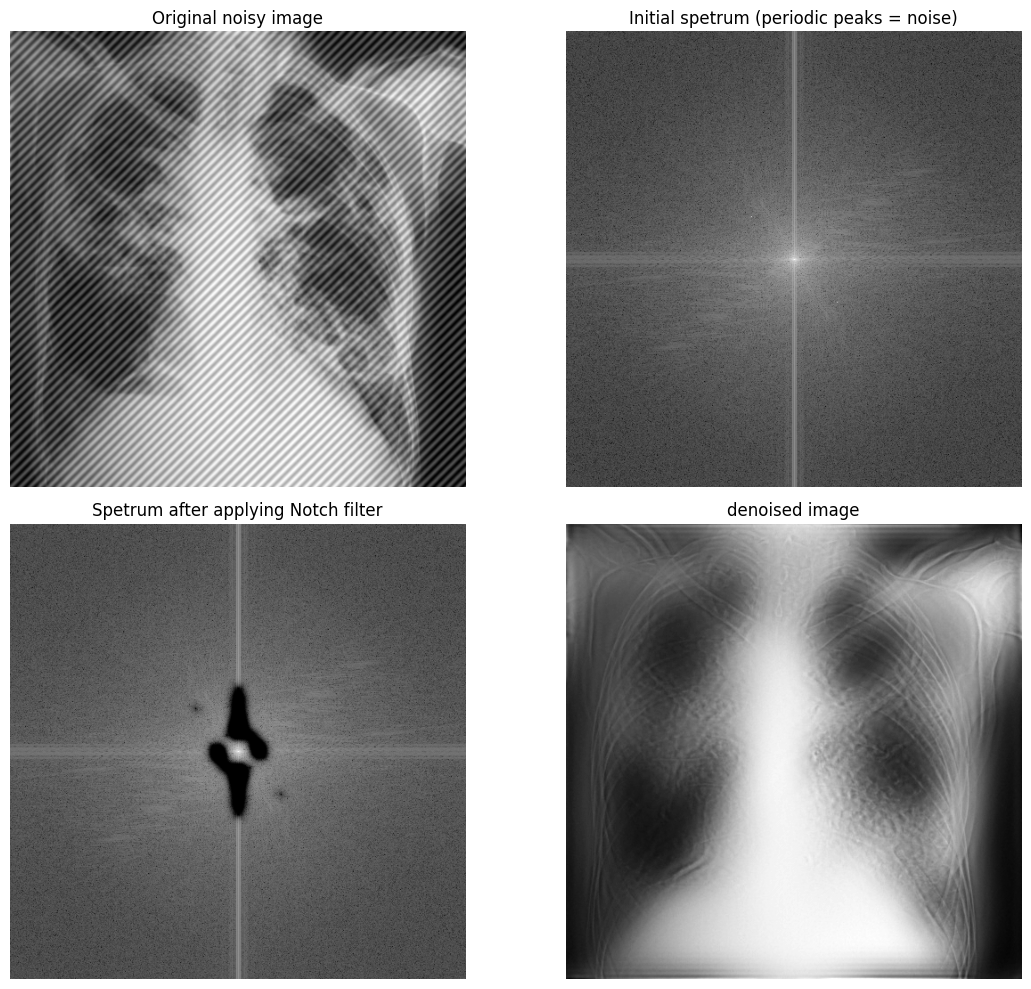

In [29]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
xray = cv2.imread("./files/xray.png", cv2.IMREAD_GRAYSCALE)
if xray is None:
  raise FileNotFoundError("Image not found.")

H, W = xray.shape
cy, cx = H // 2, W // 2

# 2. DFT and then shifting to the center
dft = np.fft.fft2(xray.astype(np.float64))
dft_shift = np.fft.fftshift(dft)
magnitude = np.abs(dft_shift)
log_mag = np.log1p(magnitude) # ln(1 + mag). avoid -inf

log_mag_vis = ((log_mag - log_mag.min()) / (log_mag.max() - log_mag.min()) * 255).astype(np.uint8)

# finding periodic noise.
Y, X = np.ogrid[:H, :W]
dist_from_center = np.sqrt((Y - cy) ** 2 + (X - cx) ** 2)

# Adaptive thresholding starting from the center of the image
outer_region = log_mag[dist_from_center > 20]
spike_threshold = np.mean(outer_region) + 3.8 * np.std(outer_region)

noise_peaks_mask = (log_mag > spike_threshold) & (dist_from_center > 20)
peak_coords = np.argwhere(noise_peaks_mask)

# 4. ساخت فیلتر میان‌نگذر گوسی (Gaussian Notch Reject Filter) حول قله‌های شناسایی‌شده
notch_filter = np.ones((H, W), dtype=np.float64)
notch_radius = 6.0  # پهنای باند حذف حول هر قله فرکانسی

for py, px in peak_coords:
  d_pos = np.sqrt((Y - py) ** 2 + (X - px) ** 2)
  # حذف قله و ناحیه اطراف آن با تابع گوسی معکوس
  notch_filter *= 1.0 - np.exp(-(d_pos**2) / (2.0 * notch_radius**2))

# اعمال فیلتر روی طیف فرکانسی شیفت‌یافته
filtered_dft_shift = dft_shift * notch_filter
filtered_log_mag = np.log1p(np.abs(filtered_dft_shift))
filtered_log_mag_vis = (
    (filtered_log_mag - filtered_log_mag.min())
    / (filtered_log_mag.max() - filtered_log_mag.min())
    * 255
).astype(np.uint8)

# 5. بازگشت به حوزه مکان با تبدیل فوریه معکوس
f_ishift = np.fft.ifftshift(filtered_dft_shift)
denoised_xray = np.real(np.fft.ifft2(f_ishift))
denoised_xray_vis = np.clip(denoised_xray, 0, 255).astype(np.uint8)

# ذخیره تصویر خروجی
cv2.imwrite("xray_denoised.png", denoised_xray_vis)

# نمایش فرآیند شناسایی و حذف نویز در حوزه مکان و فرکانس
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(xray, cmap="gray")
axes[0, 0].set_title("Original noisy image")
axes[0, 0].axis("off")

axes[0, 1].imshow(log_mag_vis, cmap="gray")
axes[0, 1].set_title("Initial spetrum (periodic peaks = noise)")
axes[0, 1].axis("off")

axes[1, 0].imshow(filtered_log_mag_vis, cmap="gray")
axes[1, 0].set_title("Spetrum after applying Notch filter")
axes[1, 0].axis("off")

axes[1, 1].imshow(denoised_xray_vis, cmap="gray")
axes[1, 1].set_title("denoised image")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

Detected frequency peaks: 22


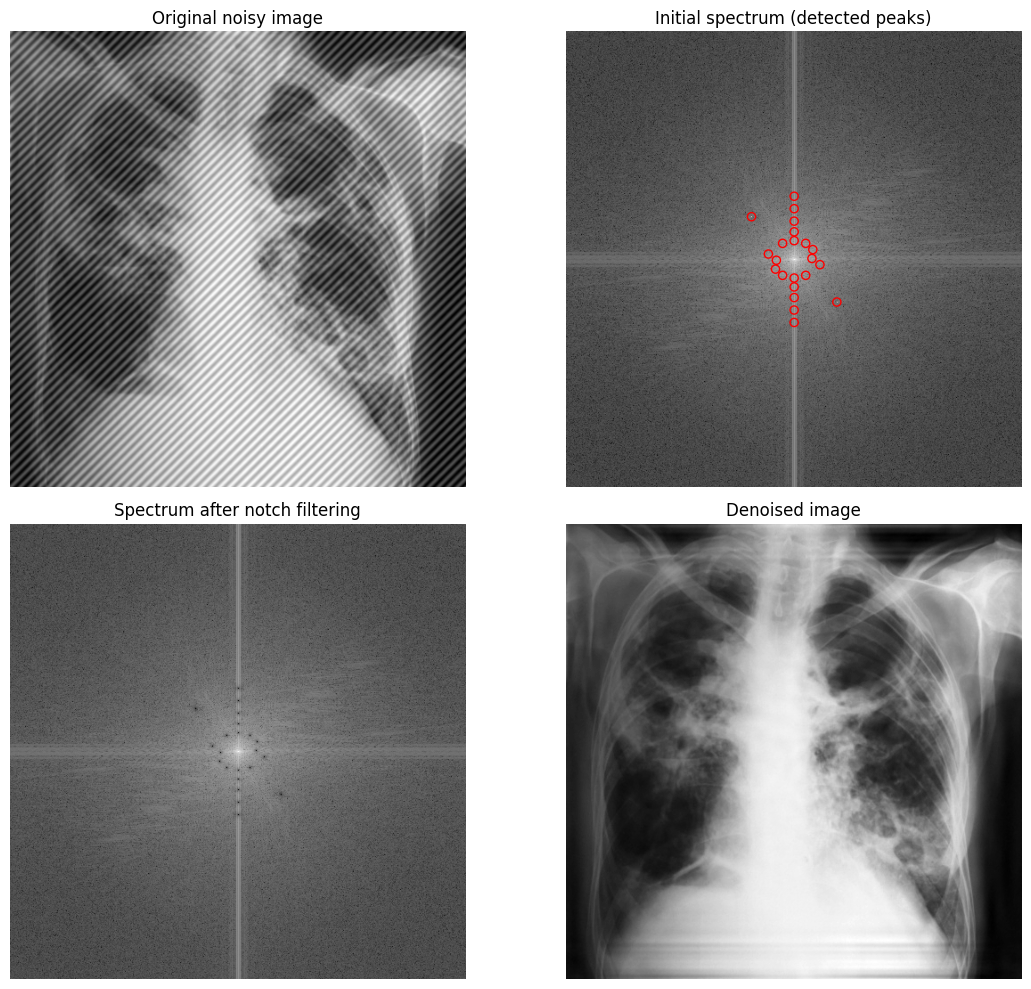

In [5]:

import cv2
import matplotlib.pyplot as plt
import numpy as np


# --------------------------------------------------
# 1. Read grayscale image
# --------------------------------------------------

xray = cv2.imread("./files/xray.png", cv2.IMREAD_GRAYSCALE)

if xray is None:
    raise FileNotFoundError("Image not found.")

H, W = xray.shape
cy, cx = H // 2, W // 2


# --------------------------------------------------
# 2. Compute DFT and shift zero frequency to center
# --------------------------------------------------

dft = cv2.dft(
    xray.astype(np.float32),
    flags=cv2.DFT_COMPLEX_OUTPUT
)

dft_shift = np.roll(
    dft,
    shift=(H // 2, W // 2),
    axis=(0, 1)
)

magnitude = cv2.magnitude(
    dft_shift[:, :, 0],
    dft_shift[:, :, 1]
)

log_mag = np.log1p(magnitude)


# --------------------------------------------------
# 3. Detect periodic noise peaks
# --------------------------------------------------

Y, X = np.ogrid[:H, :W]

dist_from_center = np.sqrt(
    (Y - cy) ** 2 + (X - cx) ** 2
)

# Ignore the low-frequency region around DC
min_center_distance = 20

outer_region = log_mag[
    dist_from_center > min_center_distance
]

# Adaptive threshold
threshold_k = 3.8

spike_threshold = (
    np.mean(outer_region)
    + threshold_k * np.std(outer_region)
)

# Find local maxima using a 3x3 neighborhood
neighborhood_max = log_mag.copy()

for dy in range(-1, 2):
    for dx in range(-1, 2):
        shifted = np.roll(
            log_mag,
            shift=(dy, dx),
            axis=(0, 1)
        )
        neighborhood_max = np.maximum(
            neighborhood_max,
            shifted
        )

local_maxima = log_mag >= neighborhood_max

candidate_mask = (
    local_maxima
    & (log_mag > spike_threshold)
    & (dist_from_center > min_center_distance)
)

candidate_coords = np.argwhere(candidate_mask)

# Sort candidates by intensity, strongest first
candidate_scores = log_mag[
    candidate_coords[:, 0],
    candidate_coords[:, 1]
]

order = np.argsort(candidate_scores)[::-1]

candidate_coords = candidate_coords[order]


# --------------------------------------------------
# 4. Non-maximum suppression and symmetric peaks
# --------------------------------------------------

min_peak_distance = 10
max_peak_pairs = 12

peak_coords = []


def is_too_close(point, existing_points, min_distance):
    py, px = point

    for ey, ex in existing_points:

        # Account for circular frequency coordinates
        dy = min(abs(py - ey), H - abs(py - ey))
        dx = min(abs(px - ex), W - abs(px - ex))

        if np.sqrt(dy**2 + dx**2) < min_distance:
            return True

    return False


for py, px in candidate_coords:

    py, px = int(py), int(px)

    # Conjugate symmetric location
    sym_y = (2 * cy - py) % H
    sym_x = (2 * cx - px) % W

    # Skip candidates that are too close to an existing peak
    if is_too_close(
        (py, px), peak_coords, min_peak_distance
    ):
        continue

    # Add both the detected peak and its symmetric counterpart
    peak_coords.append((py, px))

    if (sym_y, sym_x) != (py, px):
        peak_coords.append((sym_y, sym_x))

    if len(peak_coords) >= 2 * max_peak_pairs:
        break


print("Detected frequency peaks:", len(peak_coords))


# --------------------------------------------------
# 5. Construct Gaussian Notch Reject Filter
# --------------------------------------------------

notch_filter = np.ones((H, W), dtype=np.float32)

notch_sigma = 3.0

for py, px in peak_coords:

    d_squared = (
        (Y - py) ** 2
        + (X - px) ** 2
    )

    gaussian_notch = 1.0 - np.exp(
        -d_squared / (2.0 * notch_sigma**2)
    )

    notch_filter *= gaussian_notch.astype(np.float32)


# --------------------------------------------------
# 6. Apply notch filter in frequency domain
# --------------------------------------------------

filtered_dft_shift = (
    dft_shift * notch_filter[:, :, np.newaxis]
)

filtered_magnitude = cv2.magnitude(
    filtered_dft_shift[:, :, 0],
    filtered_dft_shift[:, :, 1]
)

filtered_log_mag = np.log1p(filtered_magnitude)


# --------------------------------------------------
# 7. Inverse DFT
# --------------------------------------------------

# Reverse the frequency shift
dft_unshift = np.roll(
    filtered_dft_shift,
    shift=(-(H // 2), -(W // 2)),
    axis=(0, 1)
)

denoised_xray = cv2.idft(
    dft_unshift,
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)

denoised_xray_vis = np.clip(
    denoised_xray, 0, 255
).astype(np.uint8)


# --------------------------------------------------
# 8. Save output
# --------------------------------------------------

cv2.imwrite("xray_denoised.png", denoised_xray_vis)


# --------------------------------------------------
# 9. Visualization
# --------------------------------------------------

def normalize_for_display(image):
    image = np.asarray(image, dtype=np.float64)

    minimum = image.min()
    maximum = image.max()

    if maximum == minimum:
        return np.zeros(image.shape, dtype=np.uint8)

    return (
        (image - minimum) / (maximum - minimum) * 255
    ).astype(np.uint8)


log_mag_vis = normalize_for_display(log_mag)
filtered_log_mag_vis = normalize_for_display(filtered_log_mag)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(xray, cmap="gray")
axes[0, 0].set_title("Original noisy image")

axes[0, 1].imshow(log_mag_vis, cmap="gray")
axes[0, 1].scatter(
    [px for py, px in peak_coords],
    [py for py, px in peak_coords],
    s=35,
    facecolors="none",
    edgecolors="red"
)
axes[0, 1].set_title("Initial spectrum (detected peaks)")

axes[1, 0].imshow(filtered_log_mag_vis, cmap="gray")
axes[1, 0].set_title("Spectrum after notch filtering")

axes[1, 1].imshow(denoised_xray_vis, cmap="gray")
axes[1, 1].set_title("Denoised image")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


Peak detection threshold: 2.6429126
Selected frequency peaks: [(208, 208), (304, 304)]
Peak strength: 7.469892


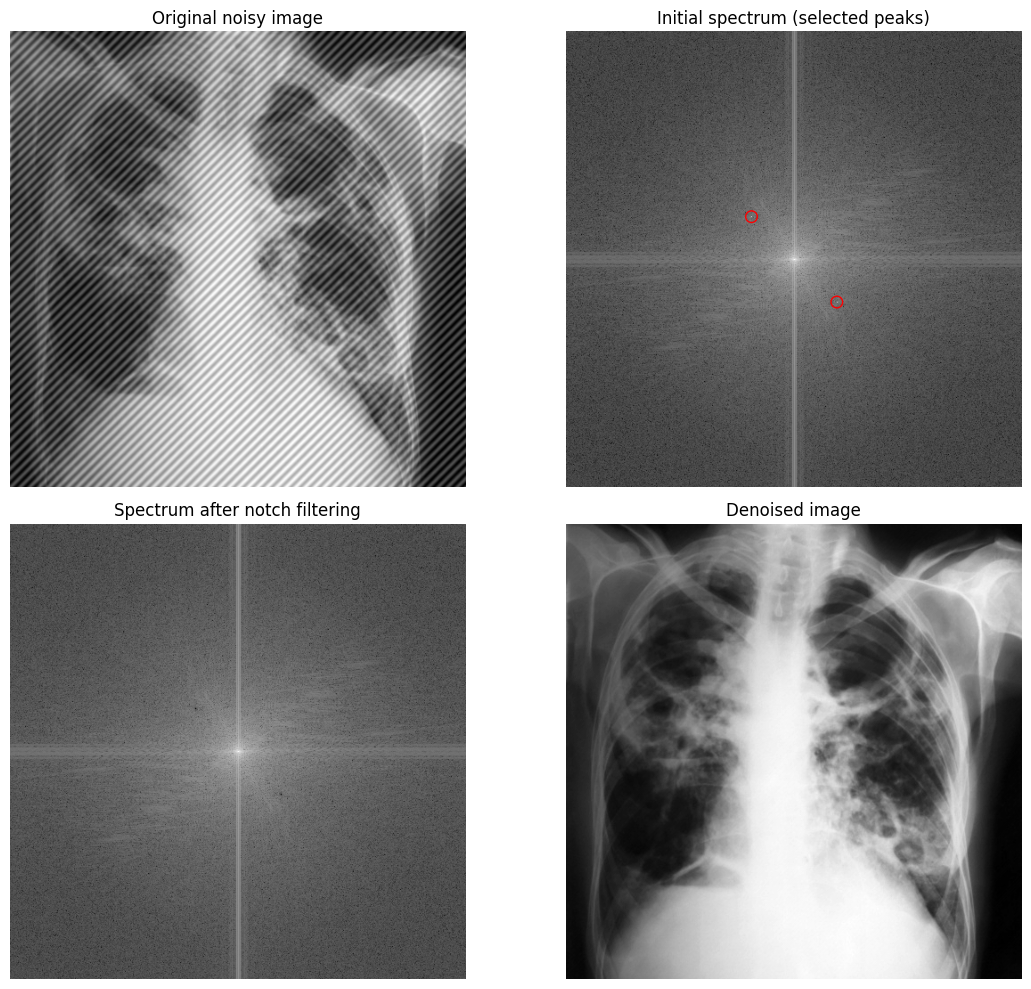

In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt


# ==================================================
# 1. Read image
# ==================================================

xray = cv2.imread("./files/xray.png", cv2.IMREAD_GRAYSCALE)

if xray is None:
    raise FileNotFoundError("Image not found.")

H, W = xray.shape

cy, cx = H // 2, W // 2 # new centers


# ==================================================
# 2. Compute DFT
# ==================================================

dft = cv2.dft(
    xray.astype(np.float32),
    flags=cv2.DFT_COMPLEX_OUTPUT # return both real and imaginary components.
)

dft_shift = np.roll(
    dft,
    shift=(cy, cx),
    axis=(0, 1)
)

magnitude = cv2.magnitude( # calculate magnitude for every frequency coordinate
    dft_shift[:, :, 0],
    dft_shift[:, :, 1]
)

log_mag = np.log1p(magnitude)


# ==================================================
# 3. Remove the local background of the spectrum
# ==================================================

# Gaussian smoothing estimates the slowly varying background of the spectrum.

background = cv2.GaussianBlur(
    log_mag,
    (0, 0),
    sigmaX=8.0,
    sigmaY=8.0
)

# Isolated frequency peaks become more prominent.
salience = log_mag - background


# ==================================================
# 4. Define the valid frequency region
# ==================================================

Y, X = np.ogrid[:H, :W]


# Y - cy represents the vertical distance of every frequency coordinate from the spectrum center.
dy = np.abs(Y - cy)
dx = np.abs(X - cx)

dist = np.sqrt(dy**2 + dx**2)

min_radius = 30 # ignore frequencies within 30 pixels of the center.
axis_exclusion = 12 # exclude a band of 12 pixels around the central horizontal and vertical axes.

valid_mask = (
    (dist > min_radius)
    & (dy > axis_exclusion)
    & (dx > axis_exclusion)
)


# ==================================================
# 5. Adaptive threshold using Median and MAD
# ==================================================

valid_values = salience[valid_mask]

median = np.median(valid_values) #The median is a measure of central tendency and is less sensitive to extreme values than the mean.

mad = np.median(np.abs(valid_values - median)) # Calculate the Median Absolute Deviation (MAD). It measures the typical deviation from the median.

robust_std = 1.4826 * mad

if robust_std < 1e-6:
    robust_std = np.std(valid_values)

threshold_k = 4.5

threshold = median + threshold_k * robust_std

print("Peak detection threshold:", threshold)


# ==================================================
# 6. Find local maxima
# ==================================================

# Detect local maxima in a 5x5 neighborhood.

local_max = cv2.dilate(
    salience.astype(np.float32),
    np.ones((5, 5), dtype=np.uint8)
)

is_local_max = salience >= local_max - 1e-6

candidate_mask = (
    valid_mask
    & is_local_max
    & (salience > threshold)
)

# Only inspect the upper half of the spectrum.
# This avoids detecting both sides of the same pair.

candidate_mask &= (np.arange(H)[:, None] < cy)

candidate_coords = np.argwhere(candidate_mask)


# ==================================================
# 7. Find the strongest symmetric peak pair
# ==================================================

candidates = []

for py, px in candidate_coords:

    py, px = int(py), int(px)

    # Symmetric frequency location
    sy = (2 * cy - py) % H
    sx = (2 * cx - px) % W

    # Both peaks must be valid local maxima
    if not valid_mask[sy, sx]:
        continue

    if not is_local_max[sy, sx]:
        continue

    # Both peaks must exceed the threshold
    if salience[sy, sx] <= threshold:
        continue

    # Use the weaker peak as the pair's score
    score = min(
        salience[py, px],
        salience[sy, sx]
    )

    candidates.append(
        (score, py, px, sy, sx)
    )


if len(candidates) == 0:
    raise RuntimeError(
        "No symmetric noise peaks found. "
        "Try reducing threshold_k."
    )

# Select ONLY the strongest symmetric pair
candidates.sort(reverse=True)

score, py, px, sy, sx = candidates[0]

peak_pair = [(py, px), (sy, sx)]

print("Selected frequency peaks:", peak_pair)
print("Peak strength:", score)


# ==================================================
# 8. Construct Gaussian Notch Reject Filter
# ==================================================

notch_filter = np.ones(
    (H, W),
    dtype=np.float32
)

notch_sigma = 2.0

for py, px in peak_pair:

    d_squared = (
        (Y - py)**2
        + (X - px)**2
    )

    gaussian_notch = 1.0 - np.exp(
        -d_squared / (2 * notch_sigma**2)
    )

    notch_filter *= gaussian_notch.astype(np.float32)


# ==================================================
# 9. Apply the notch filter
# ==================================================

filtered_dft_shift = (
    dft_shift * notch_filter[:, :, np.newaxis]
)

filtered_magnitude = cv2.magnitude(
    filtered_dft_shift[:, :, 0],
    filtered_dft_shift[:, :, 1]
)

filtered_log_mag = np.log1p(filtered_magnitude)


# ==================================================
# 10. Inverse DFT
# ==================================================

dft_unshift = np.roll(
    filtered_dft_shift,
    shift=(-cy, -cx),
    axis=(0, 1)
)

denoised_xray = cv2.idft(
    dft_unshift,
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)

denoised_xray_vis = np.clip(
    denoised_xray,
    0,
    255
).astype(np.uint8)


# ==================================================
# 11. Save result
# ==================================================

cv2.imwrite(
    "xray_denoised.png",
    denoised_xray_vis
)



# ==================================================
# 12. Visualization
# ==================================================

def normalize(image):
    image = np.asarray(image, dtype=np.float64)

    mn = image.min()
    mx = image.max()

    if mx == mn:
        return np.zeros(image.shape, dtype=np.uint8)

    return ((image - mn) / (mx - mn) * 255).astype(np.uint8)

cv2.imwrite(
    "xray_Fourier.png",
    normalize(log_mag)
)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(xray, cmap="gray")
axes[0, 0].set_title("Original noisy image")

axes[0, 1].imshow(
    normalize(log_mag),
    cmap="gray"
)

# Mark the selected symmetric frequency pair
for py, px in peak_pair:
    axes[0, 1].scatter(
        px, py,
        s=70,
        facecolors="none",
        edgecolors="red"
    )

axes[0, 1].set_title("Initial spectrum (selected peaks)")

axes[1, 0].imshow(
    normalize(filtered_log_mag),
    cmap="gray"
)

axes[1, 0].set_title("Spectrum after notch filtering")

axes[1, 1].imshow(
    denoised_xray_vis,
    cmap="gray"
)

axes[1, 1].set_title("Denoised image")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:

import cv2
import numpy as np
import matplotlib.pyplot as plt


# ==================================================
# 1. Read image
# ==================================================

xray = cv2.imread("./files/xray.png", cv2.IMREAD_GRAYSCALE)

if xray is None:
    raise FileNotFoundError("Image not found.")

H, W = xray.shape

cy, cx = H // 2, W // 2 # new centers


# ==================================================
# 2. Compute DFT
# ==================================================

dft = cv2.dft(
    xray.astype(np.float32),
    flags=cv2.DFT_COMPLEX_OUTPUT # return both real and imaginary components.
)

dft_shift = np.roll(
    dft,
    shift=(cy, cx),
    axis=(0, 1)
)

magnitude = cv2.magnitude( # calculate magnitude for every frequency coordinate
    dft_shift[:, :, 0],
    dft_shift[:, :, 1]
)

log_mag = np.log1p(magnitude)


# ==================================================
# 3. Remove the local background of the spectrum
# ==================================================

# Gaussian smoothing estimates the slowly varying background of the spectrum.

background = cv2.GaussianBlur(
    log_mag,
    (0, 0),
    sigmaX=8.0,
    sigmaY=8.0
)

# Isolated frequency peaks become more prominent.
salience = log_mag - background


# ==================================================
# 4. Define the valid frequency region
# ==================================================

Y, X = np.ogrid[:H, :W]


# Y - cy represents the vertical distance of every frequency coordinate from the spectrum center.
dy = np.abs(Y - cy)
dx = np.abs(X - cx)

dist = np.sqrt(dy**2 + dx**2)

min_radius = 30 # ignore frequencies within 30 pixels of the center.
axis_exclusion = 12 # exclude a band of 12 pixels around the central horizontal and vertical axes.

valid_mask = (
    (dist > min_radius)
    & (dy > axis_exclusion)
    & (dx > axis_exclusion)
)


# ==================================================
# 5. Adaptive threshold using Median and MAD
# ==================================================

valid_values = salience[valid_mask]

median = np.median(valid_values) #The median is a measure of central tendency and is less sensitive to extreme values than the mean.

mad = np.median(np.abs(valid_values - median)) # Calculate the Median Absolute Deviation (MAD). It measures the typical deviation from the median.

robust_std = 1.4826 * mad

if robust_std < 1e-6:
    robust_std = np.std(valid_values)

threshold_k = 1

threshold = median + threshold_k * robust_std

print("Peak detection threshold:", threshold)


# ==================================================
# 6. Find local maxima
# ==================================================

# Detect local maxima in a 5x5 neighborhood.

local_max = cv2.dilate(
    salience.astype(np.float32),
    np.ones((5, 5), dtype=np.uint8)
)

is_local_max = salience >= local_max - 1e-6

candidate_mask = (
    valid_mask
    & is_local_max
    & (salience > threshold)
)

# Only inspect the upper half of the spectrum.
# This avoids detecting both sides of the same pair.

candidate_mask &= (np.arange(H)[:, None] < cy)

candidate_coords = np.argwhere(candidate_mask)


# ==================================================
# 7. Select the two strongest symmetric peak pairs
# ==================================================

candidates.sort(reverse=True)

peak_pairs = []

min_pair_distance = 12
num_peak_pairs = 2

for score, py, px, sy, sx in candidates:

    too_close = False

    # Avoid selecting multiple nearby maxima as separate peaks
    for existing_pair in peak_pairs:

        ey, ex = existing_pair[0]

        dy = min(abs(py - ey), H - abs(py - ey))
        dx = min(abs(px - ex), W - abs(px - ex))

        if np.sqrt(dy**2 + dx**2) < min_pair_distance:
            too_close = True
            break

    if too_close:
        continue

    peak_pairs.append(
        ((py, px), (sy, sx))
    )

    if len(peak_pairs) == num_peak_pairs:
        break


if len(peak_pairs) < num_peak_pairs:
    raise RuntimeError(
        f"Only {len(peak_pairs)} symmetric peak pairs found."
    )


for i, (p1, p2) in enumerate(peak_pairs):
    print(f"Pair {i + 1}: {p1} <--> {p2}")

# ==================================================
# 8. Construct Gaussian Notch Reject Filter
# ==================================================

notch_filter = np.ones(
    (H, W),
    dtype=np.float32
)

notch_sigma = 2.0

for pair in peak_pairs:
    for py, px in pair:

        d_squared = (
            (Y - py)**2
            + (X - px)**2
        )

        gaussian_notch = 1.0 - np.exp(
            -d_squared / (2 * notch_sigma**2)
        )

        notch_filter *= gaussian_notch.astype(np.float32)


# ==================================================
# 9. Apply the notch filter
# ==================================================

filtered_dft_shift = (
    dft_shift * notch_filter[:, :, np.newaxis]
)

filtered_magnitude = cv2.magnitude(
    filtered_dft_shift[:, :, 0],
    filtered_dft_shift[:, :, 1]
)

filtered_log_mag = np.log1p(filtered_magnitude)


# ==================================================
# 10. Inverse DFT
# ==================================================

dft_unshift = np.roll(
    filtered_dft_shift,
    shift=(-cy, -cx),
    axis=(0, 1)
)

denoised_xray = cv2.idft(
    dft_unshift,
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)

denoised_xray_vis = np.clip(
    denoised_xray,
    0,
    255
).astype(np.uint8)


# ==================================================
# 11. Save result
# ==================================================

cv2.imwrite(
    "xray_denoised.png",
    denoised_xray_vis
)


# ==================================================
# 12. Visualization
# ==================================================

def normalize(image):
    image = np.asarray(image, dtype=np.float64)

    mn = image.min()
    mx = image.max()

    if mx == mn:
        return np.zeros(image.shape, dtype=np.uint8)

    return ((image - mn) / (mx - mn) * 255).astype(np.uint8)


fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(xray, cmap="gray")
axes[0, 0].set_title("Original noisy image")

axes[0, 1].imshow(
    normalize(log_mag),
    cmap="gray"
)

# Mark the selected symmetric frequency pair
for pair in peak_pairs:
    for py, px in pair:
        axes[0, 1].scatter(
            px, py,
            s=70,
            facecolors="none",
            edgecolors="red"
        )

axes[0, 1].set_title("Initial spectrum (selected peaks)")

axes[1, 0].imshow(
    normalize(filtered_log_mag),
    cmap="gray"
)

axes[1, 0].set_title("Spectrum after notch filtering")

axes[1, 1].imshow(
    denoised_xray_vis,
    cmap="gray"
)

axes[1, 1].set_title("Denoised image")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


Peak detection threshold: 0.659036


RuntimeError: Only 1 symmetric peak pairs found.